# Validating CoLoRe simulation for CMB lensing

- The CoLoRe simulation boxes were first generated by Laura Casas
- The notebook just uses the CMB lensing convergence $\kappa$ values of the boxes and validates it through the auto-spectrum.
- The kappa values can be found in `data/.../`, along with $C_{\ell}$ (and its associated errors), and a logarithmic rebinning run with `scripts/rebin_cls_kk.py`, which is the one used in this notebook.
- The notebook also compares the two CoLoRe boxes in the folder.

In [52]:
import numpy as np
import matplotlib.pyplot as plt
import camb
import healpy as hp
from scipy.integrate import quad
from scipy.constants import c

plt.rcParams.update({
    "text.usetex": True,
    "font.family": 'serif',
})

In [53]:
import sys
sys.path.append('../')
from py.rebinning import log_bin_cls    
import re

# Theory CMB lensing auto-spectrum $C_{\ell}^{\kappa \kappa}$

## setting up CAMB

In [54]:
# set the k and redshift range for the boltzmann solver
kmin, kmax = 1E-3, 100
zmin, zmax = 0, 1100
nz = 200
z_pk = zmin + np.exp(np.log(zmax - zmin + 1)*np.linspace(0, 1, nz)) - 1

# range of multipoles of the power spectrum to be studied
lmin = 2
lmax = 2500
ells = np.arange(lmin, lmax+1)

In [55]:
def get_cosmo_dict_from_param_cfg(
    cfg_path
):
    """
    Read a CoLoRe param.cfg file and extract cosmological parameters and other relevant parameters, and return them in a dictionary.
    """

    # --------------------------------------------------
    # Read file
    # --------------------------------------------------

    with open(cfg_path, "r") as f:
        text = f.read()

    # --------------------------------------------------
    # Extract cosmo_par block
    # --------------------------------------------------

    match = re.search(
        r"cosmo_par\s*=\s*\{(.*?)\};",
        text,
        re.DOTALL
    )

    if match is None:
        raise ValueError("Could not find cosmo_par block in param.cfg")

    block1 = match.group(1)

    match = re.search(
        r"global\s*=\s*\{(.*?)\};",
        text,
        re.DOTALL
    )

    if match is None:
        raise ValueError("Could not find global block in param.cfg")

    block2 = match.group(1)

    match = re.search(
        r"kappa\s*=\s*\{(.*?)\};",
        text,
        re.DOTALL
    )

    if match is None:
        raise ValueError("Could not find lensing block in param.cfg")

    block3 = match.group(1)

    # --------------------------------------------------
    # Helper function to extract values
    # --------------------------------------------------

    def extract_float(name, block):
        m = re.search(rf"{name}\s*=\s*([0-9eE+.\-]+)", block)
        if m is None:
            return None
            #raise ValueError(f"Could not find {name} in cosmo_par")
        return float(m.group(1))

    omega_M = extract_float("omega_M", block1)
    omega_L = extract_float("omega_L", block1)
    omega_B = extract_float("omega_B", block1)
    h = extract_float("h", block1)
    w = extract_float("w", block1)
    ns = extract_float("ns", block1)
    sigma_8 = extract_float("sigma_8", block1)
    As = extract_float("As", block1) if extract_float("As", block1) is not None else 2e-9

    z_max = extract_float("z_max", block2)
    z_out = extract_float("z_out", block3)

    cosmo_dict = {
        "omega_M": omega_M,
        "omega_L": omega_L,
        "omega_B": omega_B,
        "h": h,
        "w": w,
        "ns": ns,
        "sigma_8": sigma_8,
        "As": As,
        "z_max": z_max,
        "z_out": z_out
    }

    return cosmo_dict

In [56]:
def get_camb_results(
    cosmo_dict,
    z_pk,
    kmax=100.0,
    lmax=2500,
    nonlinear=False,
):
    """
    Read a cosmological parameter dictionary, extract cosmological parameters,
    and build:

    1. CAMBparams instance
    2. CAMB results object

    Parameters
    ----------
    cosmo_dict : dict
        Dictionary containing cosmological parameters

    z_pk : list or None
        Redshifts for P(k) interpolator.
        If None, defaults to [0.0]

    kmax : float
        Maximum k [1/Mpc]

    lmax : integer
        Maximum multipole

    nonlinear : bool
        Whether to use nonlinear P(k)
    """

    # --------------------------------------------------
    # Convert to CAMB inputs
    # --------------------------------------------------

    H0 = 100.0 * cosmo_dict["h"]
    ombh2 = cosmo_dict["omega_B"] * cosmo_dict["h"]**2
    omch2 = (cosmo_dict["omega_M"] - cosmo_dict["omega_B"]) * cosmo_dict["h"]**2

    # --------------------------------------------------
    # Initial CAMB params
    # --------------------------------------------------

    pars = camb.CAMBparams()

    pars.set_cosmology(
        H0=H0,
        ombh2=ombh2,
        omch2=omch2,
    )

    pars.set_dark_energy(w=cosmo_dict["w"])
    pars.InitPower.set_params(
        ns=cosmo_dict["ns"],
        As=cosmo_dict["As"]
    )

    # --------------------------------------------------
    # Matter power settings
    # --------------------------------------------------

    pars.set_matter_power(
        redshifts=z_pk,
        kmax=kmax
    )

    if nonlinear:
        pars.NonLinear = camb.model.NonLinear_both
        pars.set_for_lmax(lmax=lmax, lens_potential_accuracy=4)
    else:
        pars.set_for_lmax(lmax=lmax, lens_potential_accuracy=0)

    # Final results
    results = camb.get_results(pars)

    return results, cosmo_dict["z_max"], cosmo_dict["z_out"]

In [57]:
# get linear and non-linear matter power spectrum
cosmo_dict = get_cosmo_dict_from_param_cfg("../data/second_test_box/param.cfg")
results_lin, z_max, z_out = get_camb_results(
    cosmo_dict=cosmo_dict,
    z_pk=z_pk,
    kmax=kmax,
    lmax=lmax,
    nonlinear=False)
results_nlin, z_max, z_out = get_camb_results(
    cosmo_dict=cosmo_dict,
    z_pk=z_pk,
    kmax=kmax,
    lmax=lmax,
    nonlinear=True)

Note: redshifts have been re-sorted (earliest first)
Note: redshifts have been re-sorted (earliest first)


## manual Limber integral

In [99]:
# omoving distance of the last scattering surface
z_star = results_lin.get_derived_params().get('zstar')
chi_star = results_lin.comoving_radial_distance(z_star)
chi_max = results_lin.comoving_radial_distance(z_max)  # comoving distance of z_max
H0 = results_lin.hubble_parameter(0)
om = results_lin.get_Omega('baryon', 0) + results_lin.get_Omega('cdm', 0)
print(om)

0.31470000000012366


In [100]:
pk_interp_lin = results_lin.get_matter_power_interpolator(nonlinear=False, 
                                                      hubble_units=False, 
                                                      k_hunit=False,  
                                                      var1='delta_tot', 
                                                      var2='delta_tot')
pk_interp_nlin = results_nlin.get_matter_power_interpolator(nonlinear=True, 
                                                         hubble_units=False, 
                                                         k_hunit=False,  
                                                         var1='delta_tot', 
                                                         var2='delta_tot')

In [101]:
def w_kappa(chi, z_chi, chi_source):
    '''
    CMB lensing convergence kernel
    '''
    
    # scale factor at redshift of lensing structure
    a = 1.0 / (1.0 + z_chi)
    c_kms = c*1E-3
    
    # prefactor of the kernel
    w_prefactor = (1.5) * (H0/c_kms)**2 * om * (chi_source - chi)/chi_source
    w_geom = (chi/a)
    
    return w_prefactor * w_geom

In [102]:
def limber(chi, ell, chi_source, pk_interp, results):
    '''
    CMB lensing auto-spectrum using Limber approximation
    '''

    # converting chi to redshift
    z_chi = results.redshift_at_comoving_radial_distance(chi)
    k = (ell + 0.5) / chi  
    kp = 0.31  # k pressure parameter scale used for smoothing the power spectrum according to the colore simulation resolution


    # kernel and pk interpolator, filtering out of extrapolation k and small k
    if 1e-4 < k < kmax:
        win = w_kappa(chi, z_chi, chi_source)
        pk = pk_interp.P(z_chi, k, grid=False)
        smooth = np.exp(-(k/kp)**2)  # smoothing factor to avoid oscillations at high k 
        return (win**2 / chi**2) * pk * smooth
        
    else:
        return 0

In [103]:
#store the cls from linear and nonlinear limber approximation integration
# redshift integration up to zstar
cl_kk_lin_zs_zs = np.zeros(ells.shape)
cl_kk_nlin_zs_zs = np.zeros(ells.shape)

# redshift integration up to zmax
cl_kk_lin_zmax_zs = np.zeros(ells.shape)
cl_kk_nlin_zmax_zs = np.zeros(ells.shape)
cl_kk_lin_zmax_zmax = np.zeros(ells.shape)
cl_kk_nlin_zmax_zmax = np.zeros(ells.shape)

# manually integrate the limber approximation
for i, ell in enumerate(ells):
    
    # integral up to redshift z_star, source plane at z_star
    cl_kk_lin_zs_zs[i] = quad(limber, 0.001, chi_star, args=(ell, chi_star, pk_interp_lin, results_lin), epsabs=1E-10)[0]
    cl_kk_nlin_zs_zs[i] = quad(limber, 0.001, chi_star, args=(ell, chi_star, pk_interp_nlin, results_nlin), epsabs=1E-10)[0]
    
    # integral up to redshift z_max, source plane at z_star
    cl_kk_lin_zmax_zs[i] = quad(limber, 0.001, chi_max, args=(ell, chi_star, pk_interp_lin, results_lin), epsabs=1E-10)[0]
    cl_kk_nlin_zmax_zs[i] = quad(limber, 0.001, chi_max, args=(ell, chi_star, pk_interp_nlin, results_nlin), epsabs=1E-10)[0]

    # integral up to redshift z_max, source plane at z_max
    cl_kk_lin_zmax_zmax[i] = quad(limber, 0.001, chi_max, args=(ell, chi_max, pk_interp_lin, results_lin), epsabs=1E-10)[0]
    cl_kk_nlin_zmax_zmax[i] = quad(limber, 0.001, chi_max, args=(ell, chi_max, pk_interp_nlin, results_nlin), epsabs=1E-10)[0]

## full sky (non-Limber) integral

In [104]:
# compute the lens potential cls from camb using full curved sky without Limber approx
cl_kk_camb_lin = results_lin.get_lens_potential_cls(lmax=lmax, raw_cl=True)[2:, 0]
cl_kk_camb_lin *= ((ells * (ells + 1.0)) / 2) ** 2  # converting cls_potential to cls_kappa
cl_kk_camb_nlin = results_nlin .get_lens_potential_cls(lmax=lmax, raw_cl=True)[2:, 0]
cl_kk_camb_nlin *= ((ells * (ells + 1.0)) / 2) ** 2 # converting cls_potential to cls_kappa

# CoLoRe simulation auto-spectrum $C_{\ell}^{\kappa \kappa}$

In [105]:
first_test_box_cls_log = np.load(f'../data/first_test_box/cl_kk_log.npz')
second_test_box_cls_log = np.load(f'../data/second_test_box/cl_kk_log.npz')
ells_colore, cl_kk_colore_zmax, err_tt_zmax = first_test_box_cls_log['ells'], first_test_box_cls_log['cls'], first_test_box_cls_log['err']
ells_colore, cl_kk_colore_zs, err_tt_zs = second_test_box_cls_log['ells'], second_test_box_cls_log['cls'], second_test_box_cls_log['err']

# plotting

## latest CoLoRe box analysis

In [106]:
ells_rebin, cl_kk_lin_zmax_zs_rebin = log_bin_cls(ells, cl_kk_lin_zmax_zs, nbins=40, ell_min=2, ell_max=1535)[:2]
ells_rebin, cl_kk_lin_zmax_zmax_rebin = log_bin_cls(ells, cl_kk_lin_zmax_zmax, nbins=40, ell_min=2, ell_max=1535)[:2]

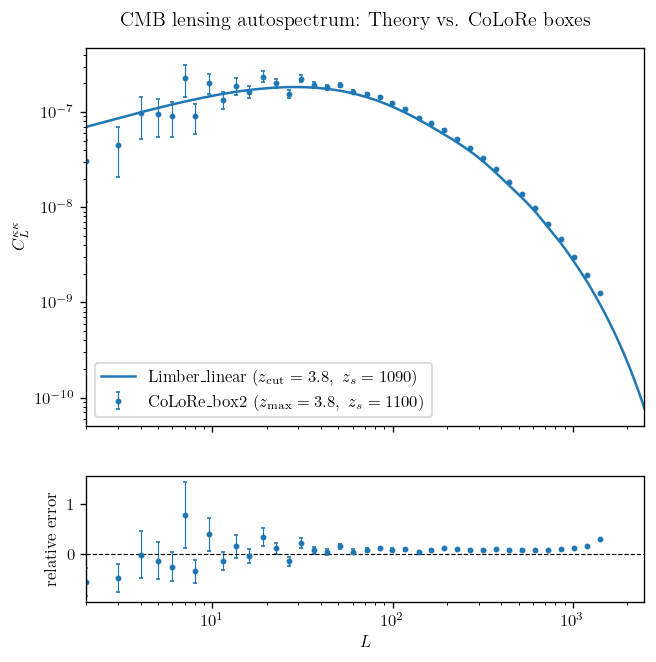

In [107]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6, 6), height_ratios=[3, 1], dpi=120, sharex=True)

# plot the rebinned CoLoRe Cls with error bars
ax1.errorbar(ells_colore, cl_kk_colore_zs, yerr=err_tt_zs, elinewidth=0.7, capsize=1.0, fmt='C0.', markersize=5.0, label=r'CoLoRe_box2 ($z_{\rm max} = 3.8, \ z_s=1100$)')

# manual limber integration full redshift
ax1.plot(ells, cl_kk_lin_zmax_zs, c='C0', ls='-', label=r'Limber_linear ($z_{\rm cut} = 3.8, \ z_s=1090$)')

ax1.set_xscale('log')
ax1.set_yscale('log')
ax1.set_xlim(lmin, lmax)
ax1.set_ylabel(r'$C_{L}^{\kappa \kappa}$')
ax1.legend()

# plot the relative error between the rebinned linear limber and the rebinned CoLoRe cls
ax2.errorbar(ells_colore, (cl_kk_colore_zs-cl_kk_lin_zmax_zs_rebin)/cl_kk_lin_zmax_zs_rebin, 
             yerr=err_tt_zs/cl_kk_lin_zmax_zs_rebin, capsize=1.0, elinewidth=0.7, fmt='C0.', markersize=5.0,
             label=r'CoLoRe_box1 vs. Limber_linear ($z_{\rm max} = z_s = 3.8$)')
ax2.axhline(0, c='k', ls='--', lw=0.7)
ax2.set_xscale('log')
ax2.set_xlabel(r'$L$')
ax2.set_ylabel('relative error')

fig.suptitle('CMB lensing autospectrum: Theory vs. CoLoRe boxes', y=0.93)

fig.savefig(f'plots/cls_kk_last_box.png', bbox_inches='tight')
fig.savefig(f'plots/cls_kk_last_box.pdf', bbox_inches='tight')
plt.show()

## compare Limber vs non-Limber with the second CoLoRe box

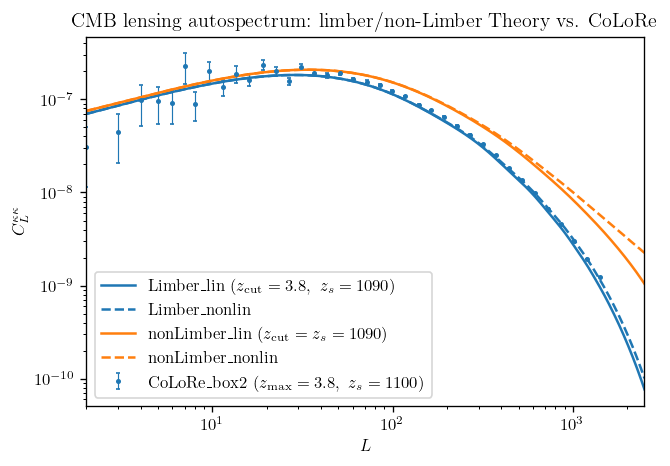

In [67]:
plt.figure(figsize=(6, 4), dpi=120)

# plot the rebinned CoLoRe Cls with error bars
plt.errorbar(ells_colore, cl_kk_colore_zs, yerr=err_tt_zs, elinewidth=0.7, capsize=1.0, fmt='C0.', markersize=4.0, label=r'CoLoRe_box2 ($z_{\rm max} = 3.8, \ z_s=1100$)')
# plt.errorbar(ells_colore, cl_kk_colore_zmax, yerr=err_tt_zmax, elinewidth=0.7, capsize=1.0, fmt='C1.', markersize=4.0, label=r'CoLoRe_box1 ($z_{\rm max} = z_s = 3.8$)')

# manual limber integration full redshift
plt.loglog(ells, cl_kk_lin_zmax_zs, c='C0', ls='-', label=r'Limber_lin ($z_{\rm cut} = 3.8, \ z_s=1090$)')
plt.loglog(ells, cl_kk_nlin_zmax_zs, c='C0', ls='--', label='Limber_nonlin')


# full sky integration full redshift
plt.loglog(ells, cl_kk_camb_lin, c='C1', ls='-', label=r'nonLimber_lin ($z_{\rm cut} = z_s=1090$)')
plt.loglog(ells, cl_kk_camb_nlin, c='C1', ls='--', label='nonLimber_nonlin')

plt.xlim(lmin, lmax)
plt.xlabel(r'$L$')
plt.ylabel(r'$C_{L}^{\kappa \kappa}$')


plt.title('CMB lensing autospectrum: limber/non-Limber Theory vs. CoLoRe')
plt.legend()

plt.savefig(f'plots/cls_kk_limber_comparison.png', bbox_inches='tight')
plt.savefig(f'plots/cls_kk_limber_comparison.pdf', bbox_inches='tight')
plt.show()

## comparing CoLoRe boxes
source plane changes between them

In [108]:
ells_rebin, cl_kk_lin_zmax_zs_rebin = log_bin_cls(ells, cl_kk_lin_zmax_zs, nbins=40, ell_min=2, ell_max=1535)[:2]
ells_rebin, cl_kk_lin_zmax_zmax_rebin = log_bin_cls(ells, cl_kk_lin_zmax_zmax, nbins=40, ell_min=2, ell_max=1535)[:2]

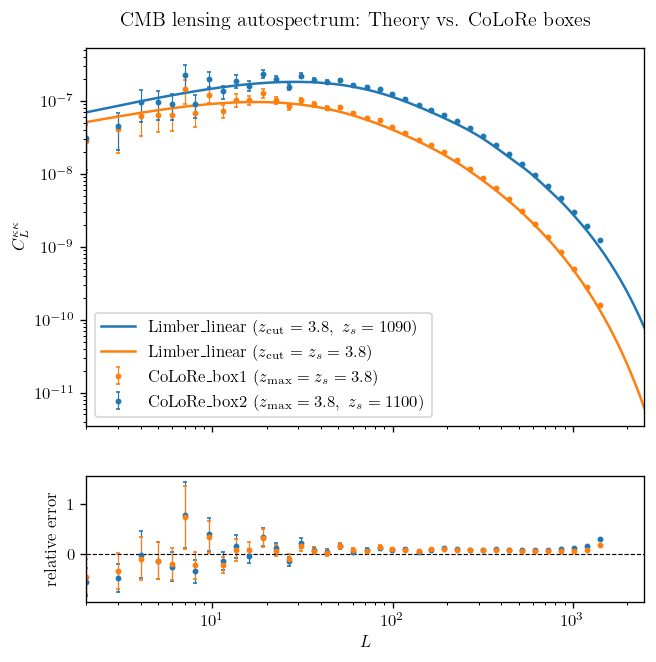

In [109]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6, 6), height_ratios=[3, 1], dpi=120, sharex=True)

# plot the rebinned CoLoRe Cls with error bars
ax1.errorbar(ells_colore, cl_kk_colore_zmax, yerr=err_tt_zmax, elinewidth=0.7, capsize=1.0, fmt='C1.', markersize=5.0, label=r'CoLoRe_box1 ($z_{\rm max} = z_s = 3.8$)')
ax1.errorbar(ells_colore, cl_kk_colore_zs, yerr=err_tt_zs, elinewidth=0.7, capsize=1.0, fmt='C0.', markersize=5.0, label=r'CoLoRe_box2 ($z_{\rm max} = 3.8, \ z_s=1100$)')

# manual limber integration full redshift
ax1.plot(ells, cl_kk_lin_zmax_zs, c='C0', ls='-', label=r'Limber_linear ($z_{\rm cut} = 3.8, \ z_s=1090$)')
ax1.plot(ells, cl_kk_lin_zmax_zmax, c='C1', ls='-', label=r'Limber_linear ($z_{\rm cut} = z_s = 3.8$)')

ax1.set_xscale('log')
ax1.set_yscale('log')
ax1.set_xlim(2, 2500)
ax1.set_ylabel(r'$C_{L}^{\kappa \kappa}$')
ax1.legend()

# plot the relative error between the rebinned linear limber and the rebinned CoLoRe cls
ax2.errorbar(ells_colore, (cl_kk_colore_zs-cl_kk_lin_zmax_zs_rebin)/cl_kk_lin_zmax_zs_rebin, 
             yerr=err_tt_zs/cl_kk_lin_zmax_zs_rebin, capsize=1.0, elinewidth=0.7, fmt='C0.', markersize=5.0,
             label=r'CoLoRe_box1 vs. Limber_linear ($z_{\rm max} = z_s = 3.8$)')
ax2.errorbar(ells_colore, (cl_kk_colore_zmax-cl_kk_lin_zmax_zmax_rebin)/cl_kk_lin_zmax_zmax_rebin, 
             yerr=err_tt_zmax/cl_kk_lin_zmax_zmax_rebin, capsize=1.0, elinewidth=0.7, fmt='C1.', markersize=5.0, 
             label=r'CoLoRe_box1 vs. Limber_linear ($z_{\rm max} = z_s = 3.8$)')
ax2.axhline(0, c='k', ls='--', lw=0.7)
ax2.set_xscale('log')
ax2.set_xlabel(r'$L$')
ax2.set_ylabel('relative error')

fig.suptitle('CMB lensing autospectrum: Theory vs. CoLoRe boxes', y=0.93)

fig.savefig(f'plots/cls_kk_boxes_comparison_kp.png', bbox_inches='tight')
fig.savefig(f'plots/cls_kk_boxes_comparison_kp.pdf', bbox_inches='tight')
plt.show()

## comparing Limber approximation: linear vs. nonlinear

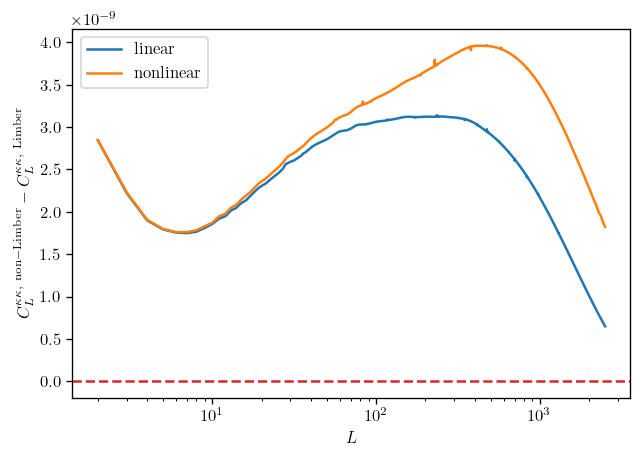

In [70]:
plt.figure(figsize=(6, 4), dpi=120)

# compare linear and nonlinear
plt.semilogx(ells, cl_kk_camb_lin - cl_kk_lin_zs_zs, label='linear')
plt.semilogx(ells, cl_kk_camb_nlin - cl_kk_nlin_zs_zs, label='nonlinear')
plt.axhline(0, c='C3', ls='--')

plt.xlabel(r'$L$')
plt.ylabel(r'$C_{L}^{\kappa \kappa, \ \rm non-Limber} - C_{L}^{\kappa \kappa, \ \rm Limber}$')

plt.legend()

plt.savefig(f'plots/cls_kk_full-vs-limber.png', bbox_inches='tight')
plt.savefig(f'plots/cls_kk_full-vs-limber.pdf', bbox_inches='tight')
plt.show()